# Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Name:** AMNA JAVED  **Reg. No:** FA23-BAI-014

## Personal Settings

In [17]:
REG_NO = "014"

SEED     = int(REG_NO[-2:])                 # last two digits
LAST     = int(REG_NO[-1])                  # last digit
HOG_CELL = 8 if LAST % 2 == 0 else 16       # even -> 8x8, odd -> 16x16
GRID     = 4 if LAST <= 4 else 6            # 0-4 -> 4x4 (16 kp), 5-9 -> 6x6 (36 kp)

print(f"Reg No: {REG_NO} | seed = {SEED} | HOG cell = {HOG_CELL}x{HOG_CELL} | SIFT grid = {GRID}x{GRID} ({GRID*GRID} keypoints)")

Reg No: 014 | seed = 14 | HOG cell = 8x8 | SIFT grid = 4x4 (16 keypoints)


In [3]:
!pip install medmnist opencv-python scikit-image scikit-learn matplotlib pandas
import warnings; warnings.filterwarnings("ignore")
import numpy as np, cv2, pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from medmnist import BloodMNIST
from skimage.feature import hog
from skimage import exposure
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

np.random.seed(SEED)
print("cv2 version:", cv2.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [medmnist]
cv2 version: 5.0.0


# Q1. Data setup

In [4]:
ORIG_LABELS = [1, 5, 6, 7]                                  # eosinophil, monocyte, neutrophil, platelet
CLASS_NAMES = ["eosinophil", "monocyte", "neutrophil", "platelet"]
N_PER_CLASS = {"train": 100, "val": 30, "test": 30}

rng = np.random.RandomState(SEED)                           # ONE generator, chosen with our seed

def make_subset(split, n_per_class):
    ds = BloodMNIST(split=split, download=True, size=64)
    X, y = ds.imgs, ds.labels.ravel()                       # X: (N,64,64,3) uint8, y: (N,)
    Xs, ys = [], []
    for new_label, old_label in enumerate(ORIG_LABELS):     # remap 1,5,6,7 -> 0,1,2,3
        idx  = np.where(y == old_label)[0]
        pick = rng.choice(idx, n_per_class, replace=False)
        Xs.append(X[pick]); ys.append(np.full(n_per_class, new_label))
    return np.concatenate(Xs), np.concatenate(ys)

def preprocess(rgb_imgs):
    """RGB 64x64 -> grayscale -> resize 128x128 (uint8)"""
    out = []
    for im in rgb_imgs:
        g = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)
        out.append(cv2.resize(g, (128, 128), interpolation=cv2.INTER_LINEAR))
    return np.array(out, dtype=np.uint8)

Xtr_rgb, ytr = make_subset("train", N_PER_CLASS["train"])
Xva_rgb, yva = make_subset("val",   N_PER_CLASS["val"])
Xte_rgb, yte = make_subset("test",  N_PER_CLASS["test"])

Xtr, Xva, Xte = preprocess(Xtr_rgb), preprocess(Xva_rgb), preprocess(Xte_rgb)

for name, X, y in [("train", Xtr, ytr), ("val", Xva, yva), ("test", Xte, yte)]:
    counts = {CLASS_NAMES[k]: int(v) for k, v in sorted(Counter(y).items())}
    print(f"{name:5s} X shape = {X.shape}, y shape = {y.shape}, dtype = {X.dtype}, class counts = {counts}")

100%|██████████| 156M/156M [01:57<00:00, 1.33MB/s]


train X shape = (400, 128, 128), y shape = (400,), dtype = uint8, class counts = {'eosinophil': 100, 'monocyte': 100, 'neutrophil': 100, 'platelet': 100}
val   X shape = (120, 128, 128), y shape = (120,), dtype = uint8, class counts = {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}
test  X shape = (120, 128, 128), y shape = (120,), dtype = uint8, class counts = {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}


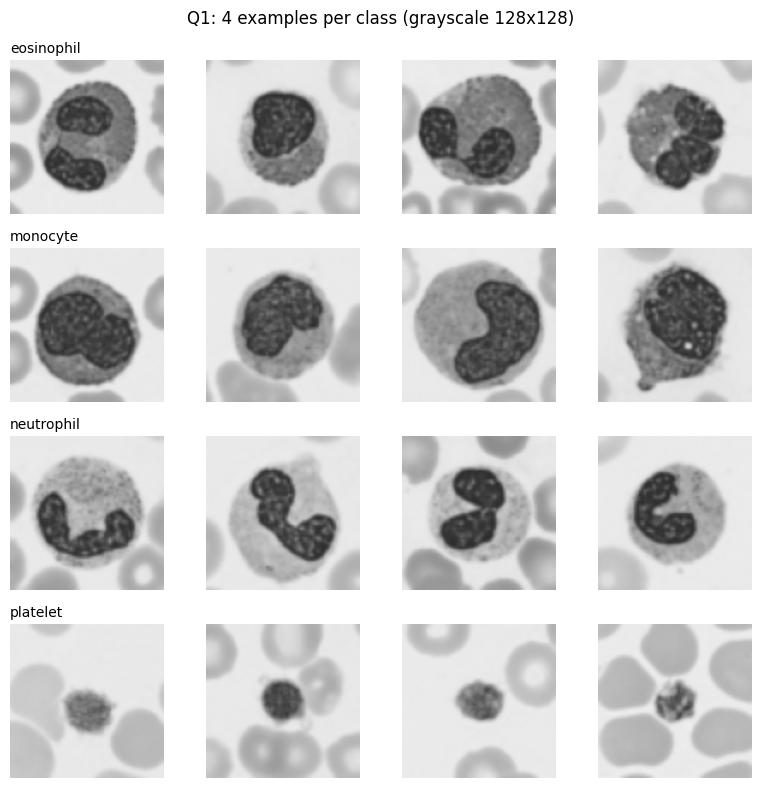

In [5]:
# Grid: 4 example training images per class (rows = classes)
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for r in range(4):
    idx = np.where(ytr == r)[0][:4]
    for c in range(4):
        axes[r, c].imshow(Xtr[idx[c]], cmap="gray", vmin=0, vmax=255)
        axes[r, c].axis("off")
        if c == 0: axes[r, c].set_title(CLASS_NAMES[r], fontsize=10, loc="left")
plt.suptitle("Q1: 4 examples per class (grayscale 128x128)")
plt.tight_layout(); plt.show()

### Shared helpers (used in Q2, Q3, Q4)

In [6]:
C_GRID = [0.1, 1, 10]

def extract(imgs, feat_fn):
    return np.array([feat_fn(im) for im in imgs])

def train_select_C(Xtr_f, ytr, Xva_f, yva, name):
    """Fit LinearSVC for each C, choose the best C on the VALIDATION set only."""
    best_acc, best_C, best_model = -1, None, None
    for C in C_GRID:
        model = make_pipeline(StandardScaler(), LinearSVC(C=C, random_state=SEED, max_iter=20000))
        model.fit(Xtr_f, ytr)
        acc = accuracy_score(yva, model.predict(Xva_f))
        print(f"[{name}] C = {C:<4} -> validation accuracy = {acc:.4f}")
        if acc > best_acc:                                   # ties keep the smaller C
            best_acc, best_C, best_model = acc, C, model
    print(f"[{name}] BEST C = {best_C} (val acc = {best_acc:.4f})")
    return best_model, best_C

def report(model, X_f, y, name):
    pred = model.predict(X_f)
    acc  = accuracy_score(y, pred)
    f1   = f1_score(y, pred, average="macro")
    cm   = confusion_matrix(y, pred)
    print(f"[{name}] Validation accuracy = {acc:.4f} | Macro-F1 = {f1:.4f}")
    print(classification_report(y, pred, target_names=CLASS_NAMES, digits=3))
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(4)); ax.set_yticks(range(4))
    ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right"); ax.set_yticklabels(CLASS_NAMES)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"{name}: confusion matrix (validation)")
    plt.tight_layout(); plt.show()
    return acc, f1, cm

# Q2. HOG + SVM (6 marks)

### Q2(a) HOG feature extraction and feature length

In [7]:
def hog_feat(img):
    return hog(img, orientations=9,
               pixels_per_cell=(HOG_CELL, HOG_CELL),
               cells_per_block=(2, 2),
               block_norm="L2-Hys", feature_vector=True)

Ftr_hog = extract(Xtr, hog_feat)
Fva_hog = extract(Xva, hog_feat)
print("HOG feature length (from code):", Ftr_hog.shape[1])
print("Train HOG matrix:", Ftr_hog.shape, "| Val HOG matrix:", Fva_hog.shape)

# hand calculation re-computed in code, to check it matches
cells_per_side  = 128 // HOG_CELL
blocks_per_side = cells_per_side - 1
manual_len = blocks_per_side**2 * (2 * 2) * 9
print(f"Manual: cells/side={cells_per_side}, blocks/side={blocks_per_side}, length={manual_len}")
assert manual_len == Ftr_hog.shape[1]

HOG feature length (from code): 8100
Train HOG matrix: (400, 8100) | Val HOG matrix: (120, 8100)
Manual: cells/side=16, blocks/side=15, length=8100


**Hand calculation of HOG feature length** (edit numbers if your cell size differs)

- Image = 128 x 128, cell = **C x C** pixels  ->  cells per side = 128 / C
- Blocks are 2 x 2 cells with stride 1 cell  ->  blocks per side = (128 / C) - 1
- Total blocks = ((128 / C) - 1)^2
- Each block has 2 x 2 cells x 9 orientations = 36 values

**Cell 8 x 8:** cells/side = 16, blocks/side = 15, blocks = 225, length = 225 x 36 = **8100**

**Cell 16 x 16:** cells/side = 8, blocks/side = 7, blocks = 49, length = 49 x 36 = **1764**

(The printed value from the code above matches the one for my cell size.)

### Q2(b) HOG pictures (one image per class)

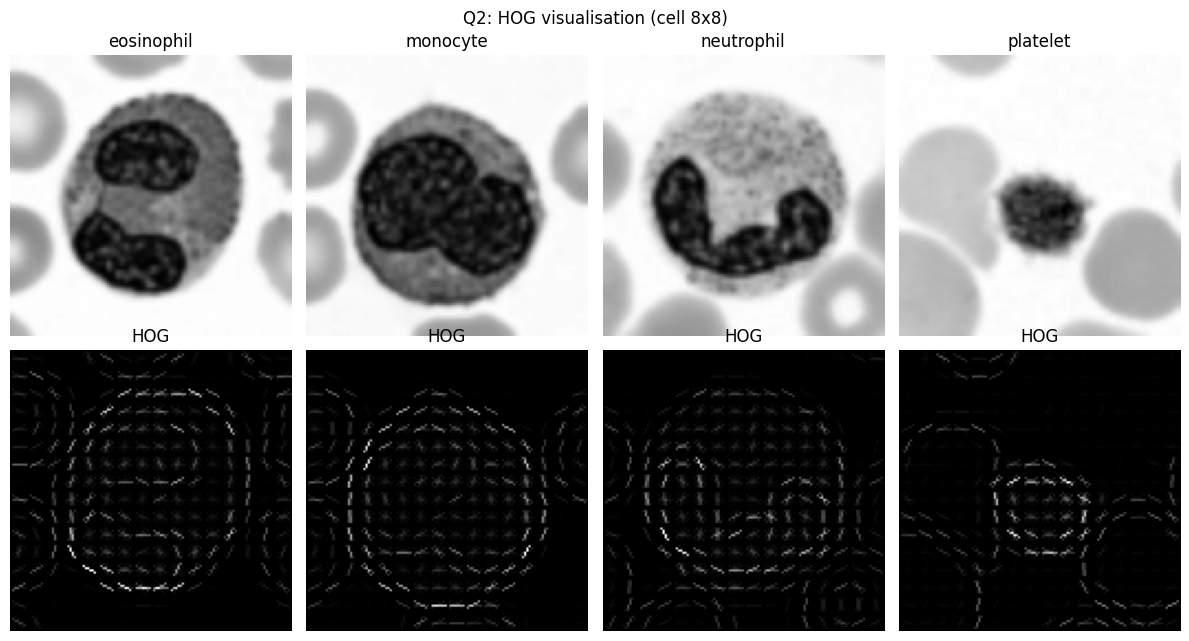

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
for c in range(4):
    img = Xtr[np.where(ytr == c)[0][0]]
    _, hog_img = hog(img, orientations=9, pixels_per_cell=(HOG_CELL, HOG_CELL),
                     cells_per_block=(2, 2), block_norm="L2-Hys", visualize=True)
    hog_img = exposure.rescale_intensity(hog_img, in_range=(0, hog_img.max() + 1e-9))
    axes[0, c].imshow(img, cmap="gray"); axes[0, c].set_title(CLASS_NAMES[c]); axes[0, c].axis("off")
    axes[1, c].imshow(hog_img, cmap="gray"); axes[1, c].set_title("HOG"); axes[1, c].axis("off")
plt.suptitle(f"Q2: HOG visualisation (cell {HOG_CELL}x{HOG_CELL})")
plt.tight_layout(); plt.show()

### Q2(c) Train SVM (choose C on validation)

[HOG+SVM] C = 0.1  -> validation accuracy = 0.7083
[HOG+SVM] C = 1    -> validation accuracy = 0.7083
[HOG+SVM] C = 10   -> validation accuracy = 0.7083
[HOG+SVM] BEST C = 0.1 (val acc = 0.7083)
[HOG+SVM] Validation accuracy = 0.7083 | Macro-F1 = 0.7076
              precision    recall  f1-score   support

  eosinophil      0.515     0.567     0.540        30
    monocyte      0.656     0.700     0.677        30
  neutrophil      0.708     0.567     0.630        30
    platelet      0.968     1.000     0.984        30

    accuracy                          0.708       120
   macro avg      0.712     0.708     0.708       120
weighted avg      0.712     0.708     0.708       120



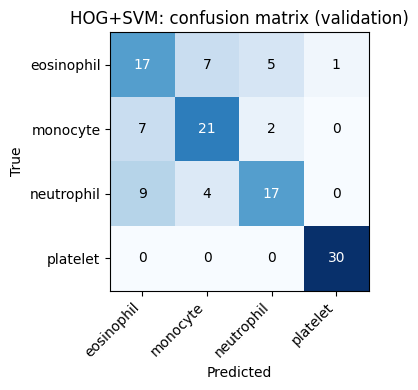

In [9]:
hog_model, hog_C = train_select_C(Ftr_hog, ytr, Fva_hog, yva, "HOG+SVM")
hog_val_acc, hog_val_f1, hog_cm = report(hog_model, Fva_hog, yva, "HOG+SVM")

# Q3. SIFT + SVM

### Q3(a) Normal SIFT detection (variable number of keypoints)

In [10]:
sift = cv2.SIFT_create()

kp_counts = []
for im in Xtr:
    kps, des = sift.detectAndCompute(im, None)
    kp_counts.append(len(kps))
kp_counts = np.array(kp_counts)

print(f"Average keypoints per image : {kp_counts.mean():.2f}")
print(f"Minimum keypoints per image : {kp_counts.min()}")
print(f"Maximum keypoints per image : {kp_counts.max()}")
print(f"Images with ZERO keypoints  : {(kp_counts == 0).sum()} / {len(kp_counts)}")

Average keypoints per image : 72.34
Minimum keypoints per image : 11
Maximum keypoints per image : 187
Images with ZERO keypoints  : 0 / 400


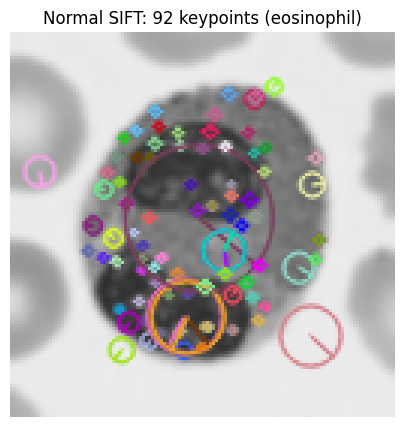

In [11]:
# Draw keypoints on one image (first image that has keypoints)
i = int(np.where(kp_counts > 0)[0][0])
kps, des = sift.detectAndCompute(Xtr[i], None)
vis = cv2.drawKeypoints(Xtr[i], kps, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5)); plt.imshow(vis[..., ::-1]); plt.axis("off")
plt.title(f"Normal SIFT: {len(kps)} keypoints ({CLASS_NAMES[ytr[i]]})"); plt.show()

**Why a different number of keypoints is a problem for an SVM:** an SVM needs every sample to be a vector of the *same* length, but normal SIFT gives each image a different number of 128-D descriptors (so the concatenated vectors have different lengths, and images with zero keypoints give nothing at all), and the keypoints are not at corresponding positions between images, so the features cannot be compared column by column.

### Q3(b) Fixed grid of keypoints (dense SIFT)

Grid 4x4 -> 16 points, spacing = 32.00px, keypoint size = 32
SIFT feature length (from code): 2048
Train SIFT matrix: (400, 2048) | Val SIFT matrix: (120, 2048)
Manual: 16 x 128 = 2048


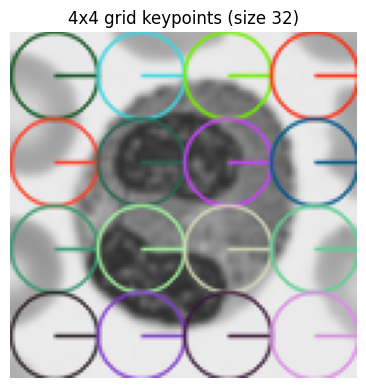

In [12]:
KP_SIZE = 32
step = 128 / GRID
GRID_PTS = [((j + 0.5) * step, (i + 0.5) * step) for i in range(GRID) for j in range(GRID)]  # (x, y) centres
print(f"Grid {GRID}x{GRID} -> {len(GRID_PTS)} points, spacing = {step:.2f}px, keypoint size = {KP_SIZE}")

def make_grid_kps():
    # new KeyPoint objects each call; angle fixed to 0 so no orientation is estimated
    return [cv2.KeyPoint(float(x), float(y), KP_SIZE, 0) for (x, y) in GRID_PTS]

def sift_grid_feat(img):
    kps, des = sift.compute(img, make_grid_kps())
    assert des is not None and des.shape == (GRID * GRID, 128), f"unexpected descriptor shape {None if des is None else des.shape}"
    return des.flatten()

Ftr_sift = extract(Xtr, sift_grid_feat)
Fva_sift = extract(Xva, sift_grid_feat)
print("SIFT feature length (from code):", Ftr_sift.shape[1])
print("Train SIFT matrix:", Ftr_sift.shape, "| Val SIFT matrix:", Fva_sift.shape)
print(f"Manual: {GRID*GRID} x 128 = {GRID*GRID*128}")
assert Ftr_sift.shape[1] == GRID * GRID * 128

# picture of the grid keypoints on one image
vis = cv2.drawKeypoints(Xtr[0], make_grid_kps(), None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(4.5, 4.5)); plt.imshow(vis[..., ::-1]); plt.axis("off")
plt.title(f"{GRID}x{GRID} grid keypoints (size {KP_SIZE})"); plt.show()

**Hand calculation of SIFT feature length**

- Each grid point gives one SIFT descriptor of 128 values (4 x 4 spatial bins x 8 orientations).
- Fixed grid -> every image has the same number of descriptors.

**4 x 4 grid:** 16 points x 128 = **2048**

**6 x 6 grid:** 36 points x 128 = **4608**

(The printed value from the code above matches the one for my grid size.)

### Q3(c) Train SVM (choose C on validation)

[SIFT+SVM] C = 0.1  -> validation accuracy = 0.7000
[SIFT+SVM] C = 1    -> validation accuracy = 0.6917
[SIFT+SVM] C = 10   -> validation accuracy = 0.6917
[SIFT+SVM] BEST C = 0.1 (val acc = 0.7000)
[SIFT+SVM] Validation accuracy = 0.7000 | Macro-F1 = 0.7012
              precision    recall  f1-score   support

  eosinophil      0.452     0.467     0.459        30
    monocyte      0.606     0.667     0.635        30
  neutrophil      0.800     0.667     0.727        30
    platelet      0.968     1.000     0.984        30

    accuracy                          0.700       120
   macro avg      0.706     0.700     0.701       120
weighted avg      0.706     0.700     0.701       120



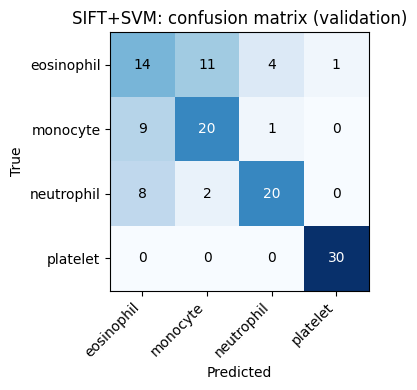

In [13]:
sift_model, sift_C = train_select_C(Ftr_sift, ytr, Fva_sift, yva, "SIFT+SVM")
sift_val_acc, sift_val_f1, sift_cm = report(sift_model, Fva_sift, yva, "SIFT+SVM")

# Q4. Robustness

### Q4(a) Prediction (written BEFORE running the evaluation)

> **Write your own prediction here before running the next cells.** Template:
>
> - **Rotation:** I think ______ (HOG / SIFT) will lose more accuracy because ______.
> - **Noise:** I think ______ (HOG / SIFT) will lose more accuracy because ______.
>
> Hints to think about: HOG bins gradient directions inside fixed cells, so what happens to them when the cell content rotates? In our dense SIFT the keypoint angle is fixed to 0, so is it rotation invariant? Noise creates many random small gradients: which descriptor sums/normalises over larger regions, and which keeps fine per-cell detail?

### Q4(b) Freeze both models and evaluate on the test set (clean / rotated 20° / noisy σ = 0.05)

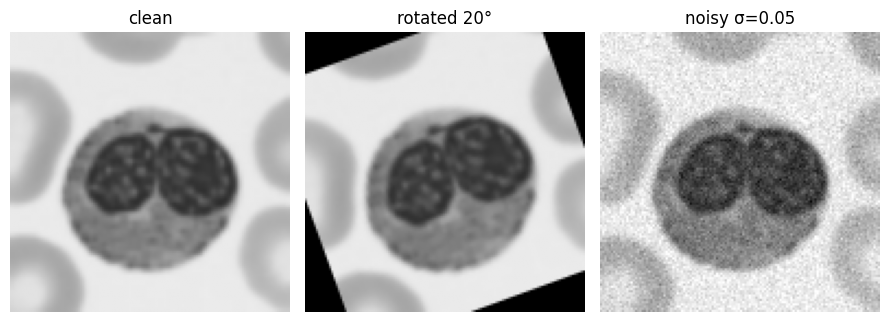

In [14]:
ROT_DEG, SIGMA = 20, 0.05

def rotate_img(img, deg=ROT_DEG):
    M = cv2.getRotationMatrix2D((64, 64), deg, 1.0)         # centre of 128x128 image
    return cv2.warpAffine(img, M, (128, 128), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=0)

noise_rng = np.random.RandomState(SEED)
def add_noise(img, sigma=SIGMA):
    x = img.astype(np.float32) / 255.0                      # scale to 0..1
    x = x + noise_rng.normal(0, sigma, x.shape)
    x = np.clip(x, 0, 1)
    return np.round(x * 255).astype(np.uint8)               # back to uint8 (SIFT needs uint8)

Xte_rot   = np.array([rotate_img(im) for im in Xte])
Xte_noisy = np.array([add_noise(im)  for im in Xte])        # fixed once -> same noisy images for both models

# Quick visual check that the transforms are right
fig, ax = plt.subplots(1, 3, figsize=(9, 3.2))
for a, im, t in zip(ax, [Xte[0], Xte_rot[0], Xte_noisy[0]], ["clean", "rotated 20°", "noisy σ=0.05"]):
    a.imshow(im, cmap="gray", vmin=0, vmax=255); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

In [15]:
# Models are FROZEN: no .fit() below, only .predict(). Features are extracted AFTER the change is applied.
variants = {"Clean": Xte, "Rotated": Xte_rot, "Noisy": Xte_noisy}
results = {"HOG + SVM": {}, "SIFT + SVM": {}}
test_preds = {"HOG + SVM": {}, "SIFT + SVM": {}}

for vname, imgs in variants.items():
    p_h = hog_model.predict(extract(imgs, hog_feat))
    p_s = sift_model.predict(extract(imgs, sift_grid_feat))
    results["HOG + SVM"][vname]  = accuracy_score(yte, p_h)
    results["SIFT + SVM"][vname] = accuracy_score(yte, p_s)
    test_preds["HOG + SVM"][vname], test_preds["SIFT + SVM"][vname] = p_h, p_s

table = pd.DataFrame(results).T[["Clean", "Rotated", "Noisy"]]
table.columns = ["Clean accuracy", "Rotated accuracy", "Noisy accuracy"]
table.index.name = "Model"
table["Drop (rot)"]   = table["Clean accuracy"] - table["Rotated accuracy"]
table["Drop (noise)"] = table["Clean accuracy"] - table["Noisy accuracy"]
print(f"Chosen C -> HOG: {hog_C} | SIFT: {sift_C}")
display(table.round(4))

Chosen C -> HOG: 0.1 | SIFT: 0.1


,Clean accuracy,Rotated accuracy,Noisy accuracy,Drop (rot),Drop (noise)
Model,,,,,
HOG + SVM,0.7417,0.6667,0.2500,0.0750,0.4917
SIFT + SVM,0.7083,0.4750,0.7167,0.2333,-0.0083


### Q4(c) Was my prediction correct?
> **Write 3 sentences using YOUR table above.** Template:
> 1. My prediction was (correct / partly correct / wrong) because HOG dropped by ____ under rotation and SIFT by ____.
> 2. Under noise, HOG dropped by ____ and SIFT by ____, so ______ was more sensitive.
> 3. A possible reason is ______ (e.g. fixed-orientation cells / fixed angle=0 in grid SIFT / noise changing small gradients).

# Q5. Short answers and AI log

### Q5(a)
> **(a) Why does HOG use block normalisation?** *
> Hint: gradient magnitudes change with lighting/contrast between regions; normalising over overlapping blocks makes the descriptor less dependent on local illumination and contrast.
>
> **(b) Why is it wrong to choose C using the test set?**
> Hint: the test set must stay unseen to give an unbiased estimate; choosing C on it leaks information, so the reported accuracy becomes optimistic and does not reflect real performance on new data.

### Q5(b) Most confused classes (computed from the validation confusion matrices)

In [16]:
def most_confused(cm, name):
    off = cm.copy().astype(int); np.fill_diagonal(off, 0)
    pairs = [(off[i, j] + off[j, i], i, j) for i in range(4) for j in range(i + 1, 4)]
    tot, i, j = max(pairs)
    print(f"[{name}] most confused pair: {CLASS_NAMES[i]} <-> {CLASS_NAMES[j]} "
          f"({off[i,j]} + {off[j,i]} = {tot} mistakes)")

most_confused(hog_cm,  "HOG+SVM")
most_confused(sift_cm, "SIFT+SVM")

[HOG+SVM] most confused pair: eosinophil <-> neutrophil (5 + 9 = 14 mistakes)
[SIFT+SVM] most confused pair: eosinophil <-> monocyte (11 + 9 = 20 mistakes)


> **Write your answer (2-3 sentences) using the printed output above:** which two classes were confused most, and why grayscale makes it harder.
> Hint: in colour, cell types differ by stain (e.g. eosinophil granules are red/orange, neutrophil nuclei purple); after grayscale conversion these colour differences become similar grey levels, leaving only shape/texture.

## 5.2 Most confused classes

Both models confused **___ and ___** the most (from the confusion matrices above). Grayscale may make this harder because the colour of the cell and its granules (stain colour) is a useful difference between some blood cells, and grayscale removes it, leaving only shape and brightness, which can look similar.

## 5.3 AI log

| Prompt (one line) | What I changed | How I checked the result |
|---|---|---|
| "Solve my HOG vs SIFT lab mid with code and explanation" | Put my registration number FA23-BAI-014, read every line, wrote my own text answers | Printed shapes and feature lengths (8100 and 2048) and matched them with hand calculation; looked at HOG pictures and keypoint drawing |